---

<br>

**Centro Universitario UAEM Zumpango**  
*Programa Educativo:* Ingeniería en Computación  
*Asignatura:* Investigación de Operaciones  

<br>

**Actividad Integradora**  
*Implementación de Modelos de Investigación de Operaciones mediante Python y Jupyter Notebook*  
*Práctica 1:* Algoritmo de Expansión Mínima  

<br>

**Objetivo General**  
Aplicar los conocimientos adquiridos en Investigación de Operaciones mediante la implementación computacional de los modelos estudiados en clase, documentando adecuadamente el proceso de solución utilizando Python y Jupyter Notebook.

**Objetivos Específicos**  
- Implementar algoritmos de optimización y análisis de redes.  
- Interpretar resultados de modelos matemáticos aplicados.  
- Desarrollar habilidades de documentación técnica mediante Markdown.  
- Relacionar los modelos con problemas del área de Tecnologías de la Información.  

<br>

**Integrantes:**  
- Zúñiga Melecio Víctor Arturo  
- Tercero Castro Dante  
- Medina López Angel Antonio  

---

### 1. Título del Problema
Diseño Óptimo de la Red de Backbone para Puntos de Acceso WiFi en un Campus Universitario.

### 2. Descripción y Planteamiento
El departamento de Tecnologías de la Información del **Centro Universitario UAEM Zumpango** ha sido encargado de desplegar una red inalámbrica (WiFi) que cubra las **8 zonas principales del campus**:

- **A**: Biblioteca
- **B**: Edificio de Ingeniería
- **C**: Rectoría
- **D**: Edificio de Ciencias
- **E**: Gimnasio / Deportes
- **F**: Cafetería
- **G**: Estacionamiento Principal
- **H**: Auditorio

Cada zona contará con un **Punto de Acceso (AP)** que debe conectarse mediante cableado de fibra óptica al switch central de distribución (backbone). Debido al alto costo del cableado por metro (incluyendo instalación en canalización), el objetivo es **interconectar los 8 puntos de acceso de modo que todos puedan comunicarse entre sí, minimizando la longitud total de fibra óptica utilizada**. 

Este problema se modela como la búsqueda de un **Árbol de Expansión Mínima (Minimum Spanning Tree, MST)** sobre un grafo ponderado.

# Diseño óptimo de la red de backbone WiFi — UAEM Zumpango
**Técnica:** Árbol de Expansión Mínima (MST) con el algoritmo de **Kruskal**, verificado con **SciPy**.

## 1. Planteamiento
8 zonas: A Biblioteca, B Ingeniería, C Rectoría, D Ciencias, E Gimnasio, F Cafetería, G Estacionamiento, H Auditorio.
Todas deben conectarse con fibra óptica usando **la menor longitud total posible**.

## 2. Modelo
- **Nodos:** las 8 zonas
- **Aristas:** tramos posibles de fibra
- **Peso:** distancia en metros
- **Objetivo:** subconjunto de aristas que conecte todo, sin ciclos y con suma mínima (n − 1 = 7 aristas)

> Nota: el enunciado no da distancias, por lo que se usan coordenadas supuestas. Puedes reemplazarlas por las reales.

## Paso 1: Importar librerías
NumPy (cálculo), Pandas (tablas), Matplotlib (gráficas) y SciPy (distancias y verificación del MST).

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import combinations
from scipy.spatial.distance import pdist, squareform
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import minimum_spanning_tree

plt.rcParams["figure.dpi"] = 100
print("Librerías cargadas correctamente")

Matplotlib is building the font cache; this may take a moment.


Librerías cargadas correctamente


## Paso 2: Datos del campus
Cada zona tiene coordenadas (x, y) en metros (hipotéticas). Con `pdist` y `squareform` calculamos la distancia euclidiana:

d(P,Q) = √((xP − xQ)² + (yP − yQ)²)

El resultado es una matriz simétrica de 8×8.

In [3]:
zonas = pd.DataFrame({
    "zona":   list("ABCDEFGH"),
    "nombre": ["Biblioteca", "Ing.", "Rectoría", "Ciencias",
               "Gimnasio", "Cafetería", "Estacionamiento", "Auditorio"],
    "x": [200, 320, 150, 400, 520, 280,  60, 480],
    "y": [250, 300, 150, 200,  80, 160,  40, 300],
}).set_index("zona")

coords = zonas[["x", "y"]].to_numpy(dtype=float)
D = np.round(squareform(pdist(coords))).astype(int)
dist = pd.DataFrame(D, index=zonas.index, columns=zonas.index)

display(zonas)
display(dist)

,nombre,x,y
zona,,,
A,Biblioteca,200,250
B,Ing.,320,300
C,Rectoría,150,150
D,Ciencias,400,200
E,Gimnasio,520,80
F,Cafetería,280,160
G,Estacionamiento,60,40
H,Auditorio,480,300


zona,A,B,C,D,E,F,G,H
zona,,,,,,,,
A,0,130,112,206,362,120,252,284
B,130,0,227,128,297,146,368,160
C,112,227,0,255,377,130,142,362
D,206,128,255,0,170,126,376,128
E,362,297,377,170,0,253,462,224
F,120,146,130,126,253,0,251,244
G,252,368,142,376,462,251,0,494
H,284,160,362,128,224,244,494,0


## Paso 3: Ubicar las zonas en el plano
Definimos funciones de dibujo reutilizables (`dibujar_nodos` y `dibujar_arista`) y graficamos el mapa del campus.

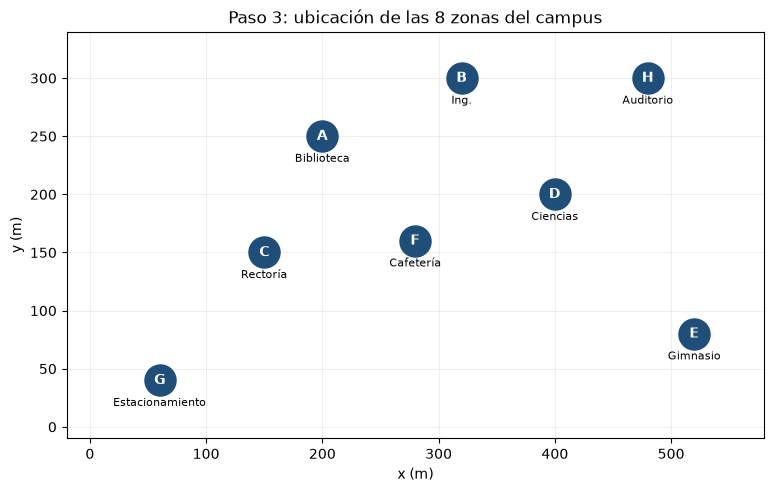

In [4]:
pos = {z: (r.x, r.y) for z, r in zonas.iterrows()}

def dibujar_nodos(ax):
    for z, (x, y) in pos.items():
        ax.scatter(x, y, s=500, color="#1f4e79", zorder=3)
        ax.text(x, y, z, color="white", ha="center", va="center",
                fontweight="bold", zorder=4)
    ax.set_xlim(-20, 580); ax.set_ylim(-10, 340)
    ax.set_aspect("equal")
    ax.set_xlabel("x (m)"); ax.set_ylabel("y (m)")
    ax.grid(alpha=0.2)

def dibujar_arista(ax, u, v, w, color="gray", lw=1.5, ls="-", alpha=1.0,
                   etiqueta=True, fs=8):
    (x1, y1), (x2, y2) = pos[u], pos[v]
    ax.plot([x1, x2], [y1, y2], color=color, lw=lw, ls=ls, alpha=alpha, zorder=1)
    if etiqueta:
        txt = "dimgray" if color == "lightgray" else color
        ax.text((x1 + x2) / 2, (y1 + y2) / 2, str(w), fontsize=fs, ha="center",
                va="center", color=txt, zorder=2,
                bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85))

fig, ax = plt.subplots(figsize=(9, 5.5))
dibujar_nodos(ax)
for z, r in zonas.iterrows():
    ax.text(r.x, r.y - 22, r.nombre, ha="center", fontsize=8)
ax.set_title("Paso 3: ubicación de las 8 zonas del campus")
plt.show()

## Paso 4: El grafo completo
Con 8 nodos hay C(8,2) = 28 conexiones posibles. Construimos la lista de aristas (u, v, peso) y graficamos el grafo completo.

Número de aristas: 28
Longitud total si instalamos TODAS: 6786 m


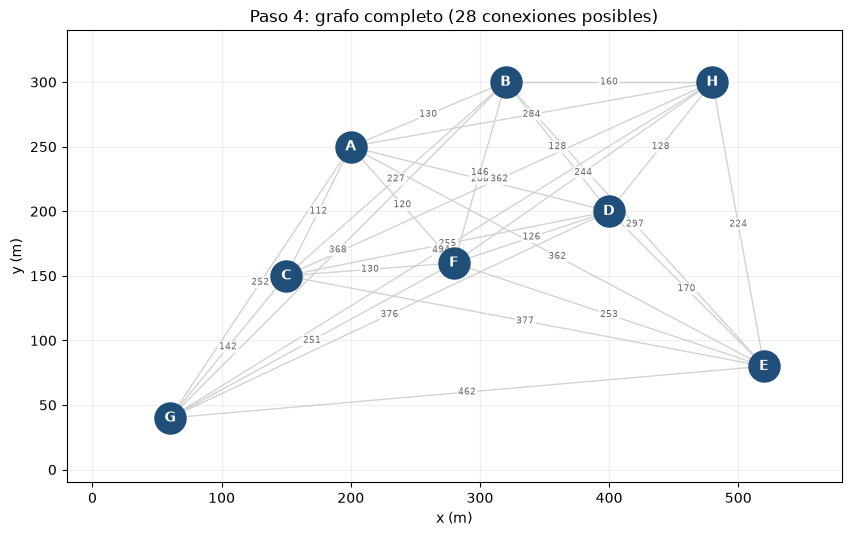

In [5]:
aristas = pd.DataFrame(
    [(u, v, int(dist.loc[u, v])) for u, v in combinations(zonas.index, 2)],
    columns=["u", "v", "peso"]
)
print(f"Número de aristas: {len(aristas)}")
print(f"Longitud total si instalamos TODAS: {aristas['peso'].sum()} m")

fig, ax = plt.subplots(figsize=(10, 6.5))
dibujar_nodos(ax)
for _, f in aristas.iterrows():
    dibujar_arista(ax, f.u, f.v, f.peso, color="lightgray", lw=1, fs=6.5)
ax.set_title("Paso 4: grafo completo (28 conexiones posibles)")
plt.show()

## Paso 5: Kruskal — ordenar las aristas
**Idea (greedy):**
1. Ordena las aristas de menor a mayor longitud.
2. Recórrelas: si conectan dos grupos distintos, se **aceptan**; si forman un ciclo, se **rechazan**.
3. Detente al tener n − 1 = 7 aristas aceptadas.

Aquí solo ordenamos y graficamos las longitudes.

,u,v,peso
1,A,C,112
2,A,F,120
3,D,F,126
4,B,D,128
5,D,H,128
6,A,B,130
7,C,F,130
8,C,G,142
9,B,F,146
10,B,H,160


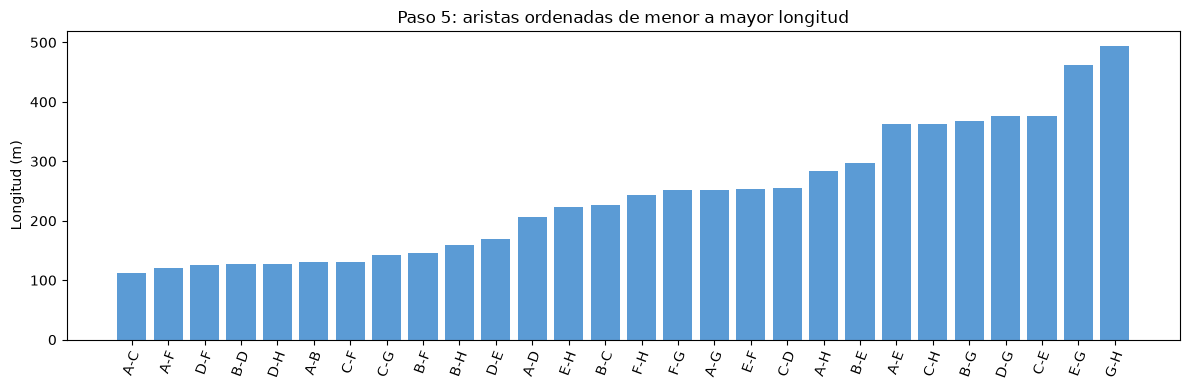

In [6]:
aristas_ord = aristas.sort_values("peso", kind="stable").reset_index(drop=True)
aristas_ord.index = aristas_ord.index + 1
display(aristas_ord)

etiquetas = aristas_ord["u"] + "-" + aristas_ord["v"]
fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(etiquetas, aristas_ord["peso"], color="#5b9bd5")
ax.set_ylabel("Longitud (m)")
ax.set_title("Paso 5: aristas ordenadas de menor a mayor longitud")
plt.xticks(rotation=70)
plt.tight_layout()
plt.show()

## Paso 6: Detectar ciclos con Union-Find
- `find(x)`: devuelve el representante del grupo de `x`.
- `union(a, b)`: junta dos grupos; devuelve `False` si ya estaban unidos (¡ciclo!).

Al inicio cada zona es su propio grupo.

In [7]:
class UnionFind:
    def __init__(self, elementos):
        self.padre = {e: e for e in elementos}
        self.rango = {e: 0 for e in elementos}

    def find(self, x):
        while self.padre[x] != x:
            self.padre[x] = self.padre[self.padre[x]]   # compresión de caminos
            x = self.padre[x]
        return x

    def union(self, a, b):
        ra, rb = self.find(a), self.find(b)
        if ra == rb:
            return False                                 # ya conectados -> ciclo
        if self.rango[ra] < self.rango[rb]:
            ra, rb = rb, ra
        self.padre[rb] = ra
        if self.rango[ra] == self.rango[rb]:
            self.rango[ra] += 1
        return True

# Prueba rápida
uf_demo = UnionFind(["A", "B", "C"])
print(uf_demo.union("A", "B"))   # True
print(uf_demo.union("B", "A"))   # False

True
False


## Paso 7: Ejecutar Kruskal y registrar cada decisión
Recorremos las aristas ordenadas y guardamos en una bitácora si cada una fue aceptada o rechazada por ciclo, con el costo acumulado.

In [8]:
uf = UnionFind(zonas.index)
mst = []
bitacora = []

for _, f in aristas_ord.iterrows():
    u, v, w = f.u, f.v, int(f.peso)
    if uf.union(u, v):
        mst.append((u, v, w))
        decision = "Aceptada"
    else:
        decision = "Rechazada (ciclo)"
    bitacora.append({"u": u, "v": v, "peso": w, "decision": decision,
                     "costo_acumulado": sum(e[2] for e in mst)})
    if len(mst) == len(zonas) - 1:
        break

tabla = pd.DataFrame(bitacora)
tabla.index = tabla.index + 1
tabla.index.name = "paso"
display(tabla)
print(f"Aristas examinadas: {len(tabla)} de {len(aristas_ord)}")

,u,v,peso,decision,costo_acumulado
paso,,,,,
1,A,C,112,Aceptada,112
2,A,F,120,Aceptada,232
3,D,F,126,Aceptada,358
4,B,D,128,Aceptada,486
5,D,H,128,Aceptada,614
6,A,B,130,Rechazada (ciclo),614
7,C,F,130,Rechazada (ciclo),614
8,C,G,142,Aceptada,756
9,B,F,146,Rechazada (ciclo),756


Aristas examinadas: 11 de 28


## Paso 8: Construcción del árbol, arista por arista
- Rojo: arista recién aceptada
- Azul: aristas aceptadas antes
- Gris punteado: aristas rechazadas por formar ciclo

El último recuadro (verde) es el árbol terminado.

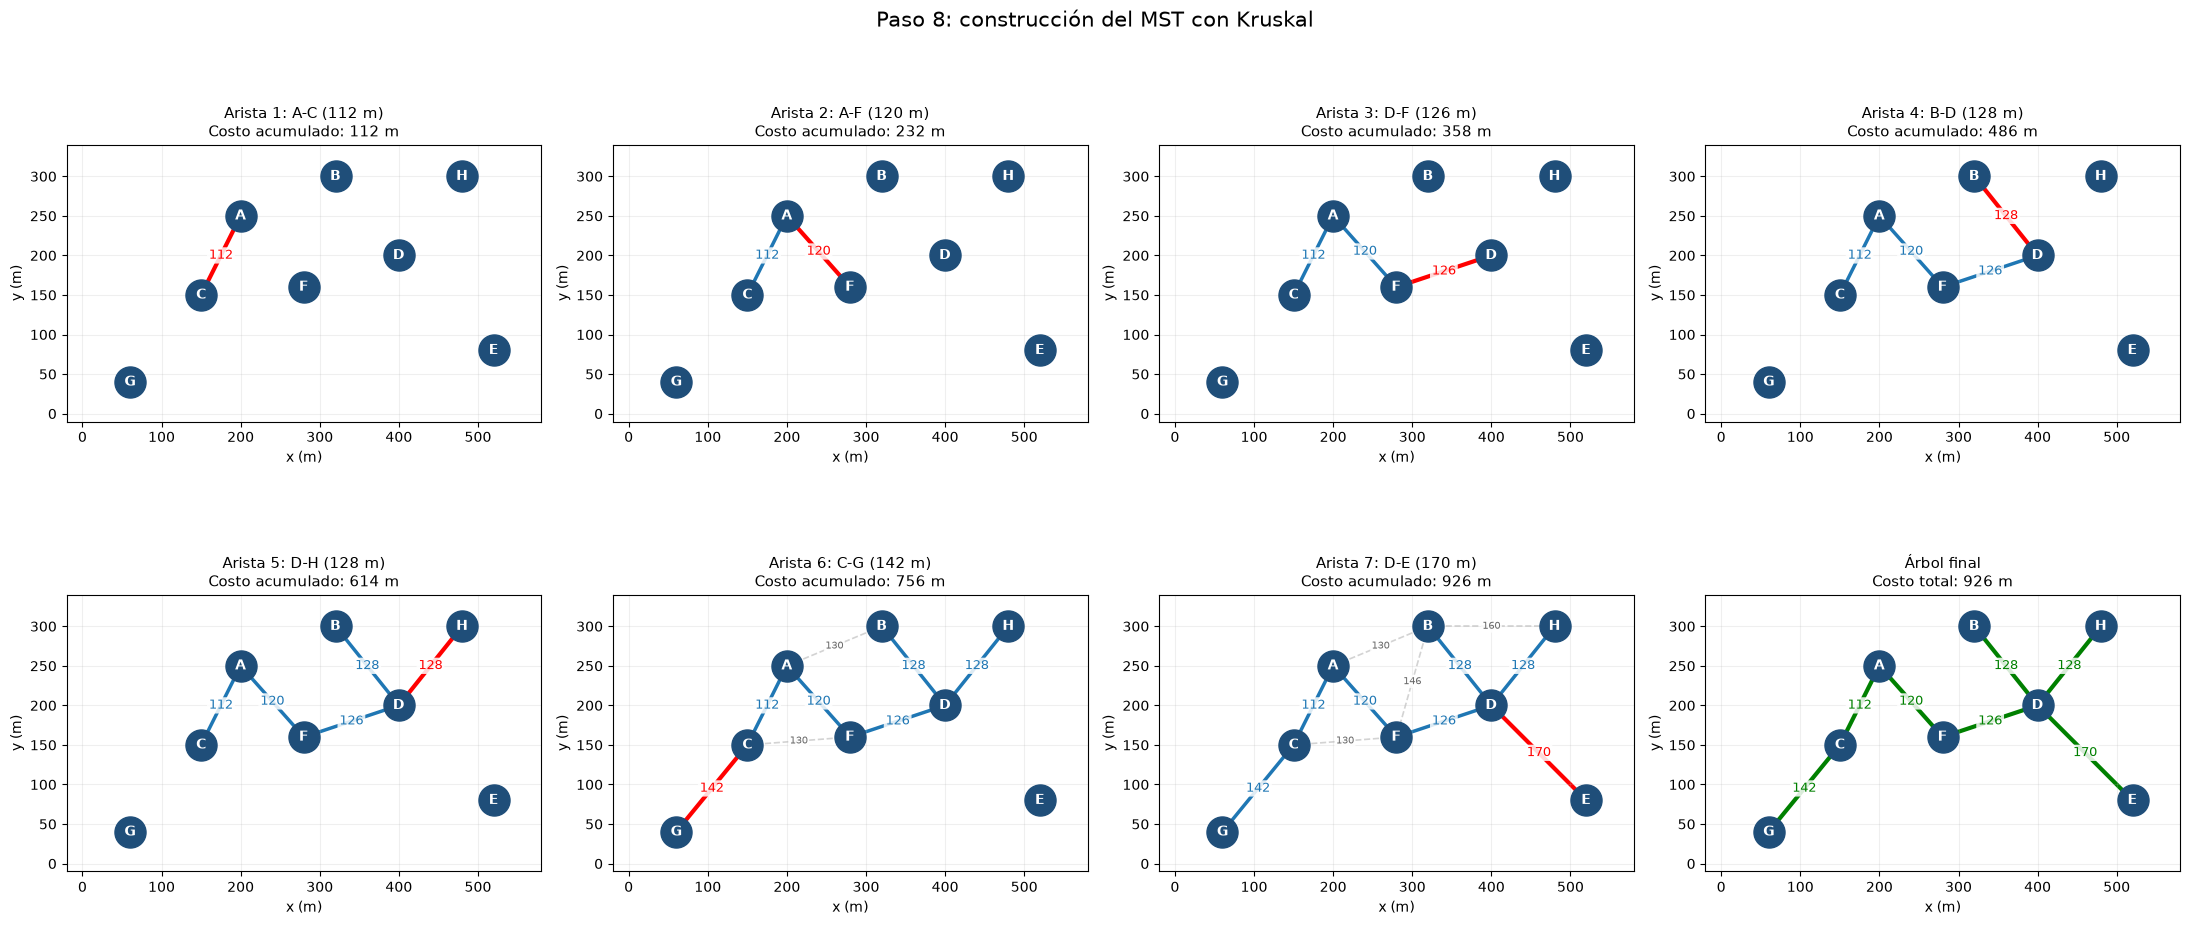

In [9]:
idx_aceptadas = [i for i, b in enumerate(bitacora) if b["decision"] == "Aceptada"]

fig, axes = plt.subplots(2, 4, figsize=(22, 10))
axes = axes.ravel()

for k, idx in enumerate(idx_aceptadas):
    ax = axes[k]
    dibujar_nodos(ax)
    for i in range(idx + 1):
        b = bitacora[i]
        if b["decision"] != "Aceptada":
            dibujar_arista(ax, b["u"], b["v"], b["peso"], color="lightgray",
                           lw=1.2, ls="--", fs=7)
        elif i == idx:
            dibujar_arista(ax, b["u"], b["v"], b["peso"], color="red", lw=3, fs=9)
        else:
            dibujar_arista(ax, b["u"], b["v"], b["peso"], color="#1f77b4", lw=2.5, fs=9)
    b = bitacora[idx]
    ax.set_title(f"Arista {k+1}: {b['u']}-{b['v']} ({b['peso']} m)\n"
                 f"Costo acumulado: {b['costo_acumulado']} m", fontsize=11)

ax = axes[7]
dibujar_nodos(ax)
for u, v, w in mst:
    dibujar_arista(ax, u, v, w, color="green", lw=3, fs=9)
ax.set_title(f"Árbol final\nCosto total: {sum(e[2] for e in mst)} m", fontsize=11)

plt.suptitle("Paso 8: construcción del MST con Kruskal", fontsize=15)
plt.tight_layout()
plt.show()

## Paso 9: Verificación con SciPy
Usamos `scipy.sparse.csgraph.minimum_spanning_tree` sobre la matriz de distancias y comparamos aristas y costo con nuestro Kruskal.

In [10]:
arbol_scipy = minimum_spanning_tree(csr_matrix(D))
filas, cols = arbol_scipy.nonzero()
nombres = list(zonas.index)

aristas_scipy = sorted(
    tuple(sorted((nombres[i], nombres[j]))) + (int(arbol_scipy[i, j]),)
    for i, j in zip(filas, cols)
)
aristas_kruskal = sorted(tuple(sorted((u, v))) + (w,) for u, v, w in mst)

costo_scipy = int(arbol_scipy.sum())
costo_kruskal = sum(w for _, _, w in mst)

print("Kruskal (nuestro):", aristas_kruskal)
print("SciPy            :", aristas_scipy)
print(f"\nCosto Kruskal = {costo_kruskal} m | Costo SciPy = {costo_scipy} m")
print("¿Mismas aristas?  ->", aristas_kruskal == aristas_scipy)
print("¿Mismo costo?     ->", costo_kruskal == costo_scipy)

Kruskal (nuestro): [('A', 'C', 112), ('A', 'F', 120), ('B', 'D', 128), ('C', 'G', 142), ('D', 'E', 170), ('D', 'F', 126), ('D', 'H', 128)]
SciPy            : [('A', 'C', 112), ('A', 'F', 120), ('B', 'D', 128), ('C', 'G', 142), ('D', 'E', 170), ('D', 'F', 126), ('D', 'H', 128)]

Costo Kruskal = 926 m | Costo SciPy = 926 m
¿Mismas aristas?  -> True
¿Mismo costo?     -> True


## Paso 10: Resultado final sobre el mapa
El MST (verde, grueso) sobre el grafo completo (gris tenue), más una tabla con cada tramo de fibra.

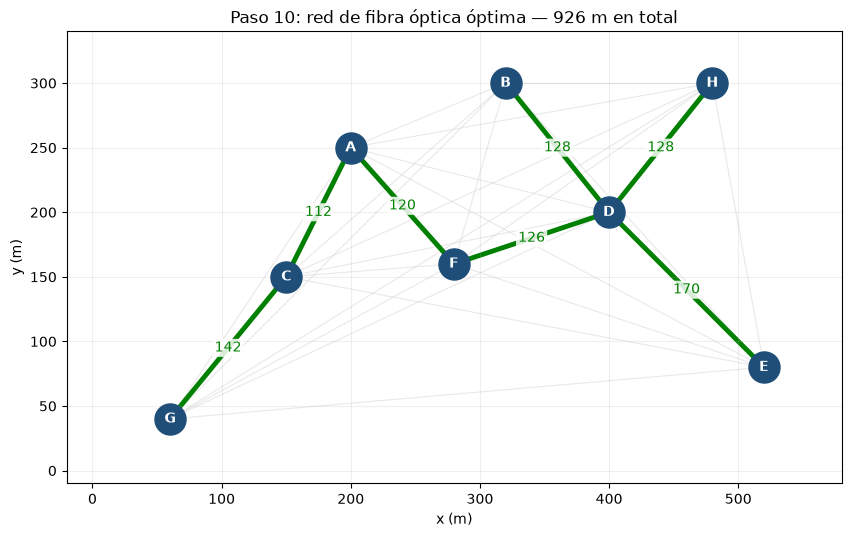

,Tramo,Zona 1,Zona 2,Longitud (m)
1,Biblioteca ↔️ Rectoría,A,C,112
2,Biblioteca ↔️ Cafetería,A,F,120
3,Ciencias ↔️ Cafetería,D,F,126
4,Ing. ↔️ Ciencias,B,D,128
5,Ciencias ↔️ Auditorio,D,H,128
6,Rectoría ↔️ Estacionamiento,C,G,142
7,Ciencias ↔️ Gimnasio,D,E,170


In [11]:
fig, ax = plt.subplots(figsize=(10, 6.5))
dibujar_nodos(ax)
en_mst = {tuple(sorted((u, v))) for u, v, _ in mst}
for _, f in aristas.iterrows():
    if tuple(sorted((f.u, f.v))) not in en_mst:
        dibujar_arista(ax, f.u, f.v, f.peso, color="lightgray", lw=0.8,
                       alpha=0.5, etiqueta=False)
for u, v, w in mst:
    dibujar_arista(ax, u, v, w, color="green", lw=3.5, fs=10)
ax.set_title(f"Paso 10: red de fibra óptica óptima — {costo_kruskal} m en total")
plt.show()

resultado = pd.DataFrame(mst, columns=["Zona 1", "Zona 2", "Longitud (m)"])
resultado["Tramo"] = resultado["Zona 1"].map(zonas["nombre"]) + " ↔️ " + resultado["Zona 2"].map(zonas["nombre"])
resultado.index = resultado.index + 1
display(resultado[["Tramo", "Zona 1", "Zona 2", "Longitud (m)"]])

## Paso 11: Comparación con otras topologías
- **Malla completa:** las 28 aristas.
- **Estrella:** las 7 zonas conectadas directamente a una zona central (probamos cada zona como centro).

Malla completa (28 aristas): 6786 m
Mejor estrella (centro = F, Cafetería): 1270 m
MST (7 aristas): 926 m


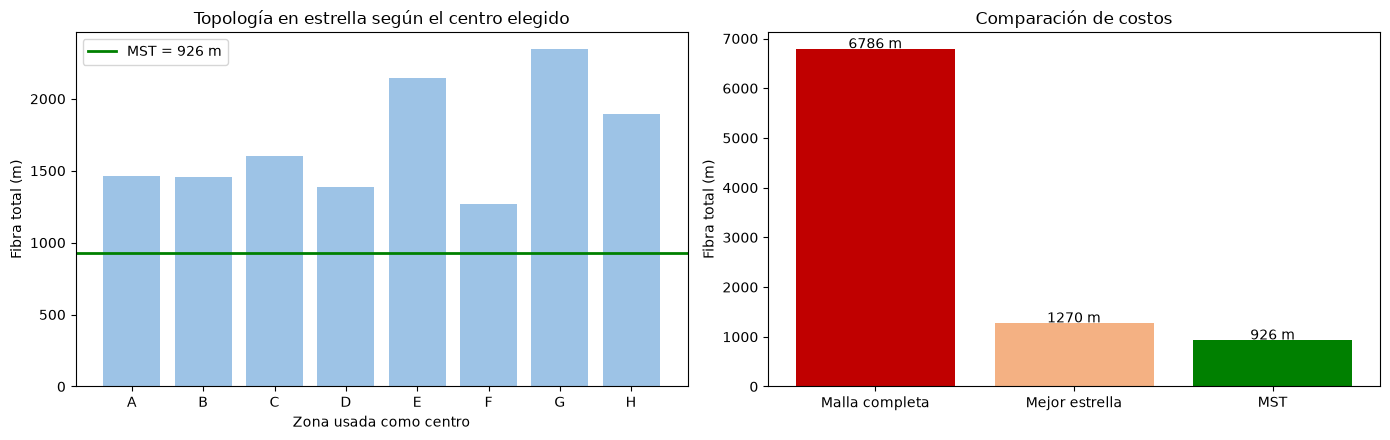

In [13]:
costo_total = int(aristas["peso"].sum())
estrella = dist.sum(axis=1)
mejor_centro = estrella.idxmin()

print(f"Malla completa (28 aristas): {costo_total} m")
print(f"Mejor estrella (centro = {mejor_centro}, {zonas.loc[mejor_centro, 'nombre']}): {estrella[mejor_centro]} m")
print(f"MST (7 aristas): {costo_kruskal} m")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].bar(estrella.index, estrella.values, color="#9dc3e6")
axes[0].axhline(costo_kruskal, color="green", lw=2, label=f"MST = {costo_kruskal} m")
axes[0].set_xlabel("Zona usada como centro")
axes[0].set_ylabel("Fibra total (m)")
axes[0].set_title("Topología en estrella según el centro elegido")
axes[0].legend()

valores = [costo_total, estrella[mejor_centro], costo_kruskal]
axes[1].bar(["Malla completa", "Mejor estrella", "MST"], valores,
            color=["#c00000", "#f4b183", "green"])
axes[1].set_ylabel("Fibra total (m)")
axes[1].set_title("Comparación de costos")
for i, v in enumerate(valores):
    axes[1].text(i, v + 20, f"{v} m", ha="center")

plt.tight_layout()
plt.show()

## Paso 12: Interpretación de resultados
La siguiente celda calcula los indicadores clave (se actualizan solos si cambias los datos).

In [14]:
grados = pd.Series(0, index=zonas.index)
for u, v, _ in mst:
    grados[u] += 1
    grados[v] += 1

hojas = [z for z in grados.index if grados[z] == 1]
nodo_max = grados.idxmax()
tramo_largo = max(mst, key=lambda e: e[2])
ahorro_malla = 100 * (1 - costo_kruskal / costo_total)
ahorro_estrella = 100 * (1 - costo_kruskal / estrella[mejor_centro])

print(f"• Fibra mínima necesaria: {costo_kruskal} m en {len(mst)} tramos.")
print(f"• Ahorro frente a la malla completa: {ahorro_malla:.1f} % ({costo_total - costo_kruskal} m menos).")
print(f"• Ahorro frente a la mejor estrella: {ahorro_estrella:.1f} % ({estrella[mejor_centro] - costo_kruskal} m menos).")
print(f"• Zona con más conexiones: {nodo_max} ({zonas.loc[nodo_max,'nombre']}) con {grados[nodo_max]} enlaces.")
print(f"• Zonas en los extremos (1 solo enlace): {', '.join(hojas)}.")
print(f"• Tramo más largo elegido: {tramo_largo[0]}-{tramo_largo[1]} con {tramo_largo[2]} m.")
print(f"• Tramos aceptados = {len(mst)} = n - 1 = {len(zonas)-1}  ->  sin ciclos, todo conectado.")

• Fibra mínima necesaria: 926 m en 7 tramos.
• Ahorro frente a la malla completa: 86.4 % (5860 m menos).
• Ahorro frente a la mejor estrella: 27.1 % (344 m menos).
• Zona con más conexiones: D (Ciencias) con 4 enlaces.
• Zonas en los extremos (1 solo enlace): B, E, G, H.
• Tramo más largo elegido: D-E con 170 m.
• Tramos aceptados = 7 = n - 1 = 7  ->  sin ciclos, todo conectado.


---
### Práctica 2
Planificación Temporal del Despliegue de la Red WiFi del Campus UAEM Zumpango mediante el Método de Ruta Crítica (CPM).

### 2. Descripción y Planteamiento
Una vez determinada la topología óptima de cableado en la **Práctica 1**, el departamento de TI del **Centro Universitario UAEM Zumpango** necesita planificar la ejecución del proyecto de despliegue de la red WiFi. 

Se han identificado **11 actividades clave** que deben ejecutarse para completar el proyecto, desde el levantamiento de requerimientos hasta la entrega final. Cada actividad tiene una duración estimada (en días hábiles) y **relaciones de precedencia** estrictas, ya que ciertas tareas no pueden iniciar hasta que otras hayan concluido.

El objetivo es determinar:
- La **duración total del proyecto**.
- Las **actividades críticas** (aquellas que, si se retrasan, retrasan todo el proyecto).
- Las **holguras** de las actividades no críticas, para identificar dónde existe flexibilidad en la asignación de recursos.

Este problema se modela mediante el **Método de la Ruta Crítica (CPM)**, utilizando los cálculos de tiempos tempranos y tardíos.

---

### 3. Definición de Actividades del Proyecto

A continuación se presenta el desglose de las 11 actividades del proyecto, con sus respectivas duraciones y relaciones de precedencia:

| Código | Actividad                                       | Predecesoras | Duración (días) |
|:------:|:------------------------------------------------|:------------:|:---------------:|
| A      | Levantamiento de requerimientos técnicos        | —            | 3               |
| B      | Estudio de canalización y rutas de fibra        | —            | 4               |
| C      | Adquisición de equipos (switches, APs, cable)   | A            | 5               |
| D      | Diseño de topología lógica y direccionamiento   | A            | 4               |
| E      | Trámite de permisos e instalaciones físicas     | B            | 3               |
| F      | Instalación de canalización y bandejas          | E            | 6               |
| G      | Tendido de cableado de fibra óptica             | C, F         | 4               |
| H      | Configuración lógica de switches y VLANs        | D            | 3               |
| I      | Instalación física de puntos de acceso (APs)    | G            | 5               |
| J      | Pruebas de conectividad y rendimiento           | H, I         | 3               |
| K      | Documentación técnica y entrega al área usuaria | J            | 2               |

## Paso 1: Importar librerías
Solo se usan NumPy, Pandas, Matplotlib y SciPy (esta última para verificar el resultado con programación lineal).

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import linprog

## Paso 2: Datos del proyecto
Se captura cada actividad con su nombre, predecesoras y duración. La lista está en orden topológico (ninguna actividad aparece antes que sus predecesoras), lo que simplifica los cálculos.

In [16]:
act = pd.DataFrame({
    "act": list("ABCDEFGHIJK"),
    "nombre": ["Levantamiento de requerimientos", "Estudio de canalización y rutas",
               "Adquisición de equipos", "Diseño de topología lógica",
               "Permisos e instalaciones", "Instalación de canalización",
               "Tendido de fibra óptica", "Configuración de switches y VLANs",
               "Instalación de APs", "Pruebas de conectividad", "Documentación y entrega"],
    "pred": [[], [], ["A"], ["A"], ["B"], ["E"], ["C", "F"], ["D"], ["G"], ["H", "I"], ["J"]],
    "dur":  [3, 4, 5, 4, 3, 6, 4, 3, 5, 3, 2],
}).set_index("act")

tabla = act.copy()
tabla["pred"] = tabla["pred"].apply(lambda p: ", ".join(p) if p else "-")
display(tabla)

,nombre,pred,dur
act,,,
A,Levantamiento de requerimientos,-,3
B,Estudio de canalización y rutas,-,4
C,Adquisición de equipos,A,5
D,Diseño de topología lógica,A,4
E,Permisos e instalaciones,B,3
F,Instalación de canalización,E,6
G,Tendido de fibra óptica,"C, F",4
H,Configuración de switches y VLANs,D,3
I,Instalación de APs,G,5


## Paso 3: Red del proyecto
Dibujamos la red de precedencias. Definimos una función reutilizable `dibujar_red` que recibe qué texto poner en cada nodo y qué actividades resaltar. Las flechas indican "debe terminar antes de que inicie".

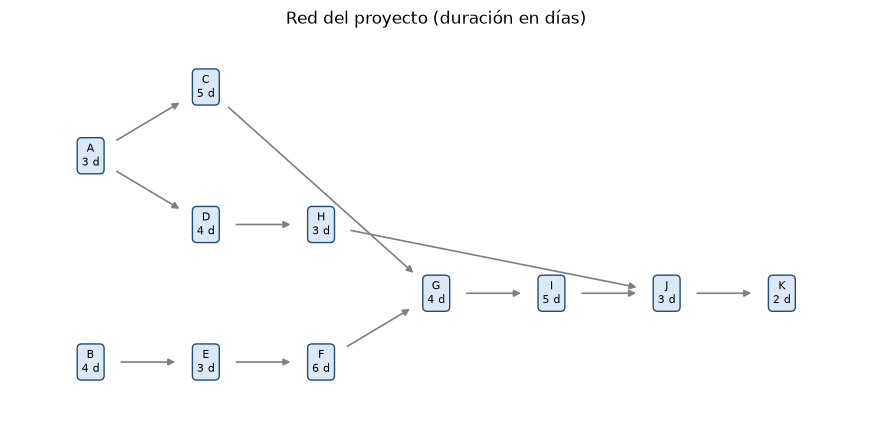

In [17]:
pos = {"A": (0, 3), "B": (0, 0), "C": (1, 4), "D": (1, 2), "E": (1, 0), "F": (2, 0),
       "H": (2, 2), "G": (3, 1), "I": (4, 1), "J": (5, 1), "K": (6, 1)}

def dibujar_red(ax, etiqueta, criticas=(), titulo=""):
    for a in act.index:
        for p in act.loc[a, "pred"]:
            rojo = p in criticas and a in criticas
            ax.annotate("", xy=pos[a], xytext=pos[p],
                        arrowprops=dict(arrowstyle="-|>", color="red" if rojo else "gray",
                                        lw=2.5 if rojo else 1.2, shrinkA=22, shrinkB=22))
    for a, (x, y) in pos.items():
        ax.text(x, y, etiqueta(a), ha="center", va="center", fontsize=8, zorder=3,
                bbox=dict(boxstyle="round,pad=0.4", fc="#ffd6d6" if a in criticas else "#dbe9f6",
                          ec="red" if a in criticas else "#1f4e79"))
    ax.set_xlim(-0.7, 6.7); ax.set_ylim(-0.8, 4.8); ax.axis("off"); ax.set_title(titulo)

fig, ax = plt.subplots(figsize=(11, 5))
dibujar_red(ax, lambda a: f"{a}\n{act.loc[a,'dur']} d",
            titulo="Red del proyecto (duración en días)")
plt.show()

## Paso 4: Paso hacia adelante (tiempos tempranos)
Se recorren las actividades de inicio a fin:

ES(a) = max(EF de sus predecesoras), EF(a) = ES(a) + duración(a)

El mayor EF de todas las actividades es la **duración total T** del proyecto.

,ES,EF
A,0,3
B,0,4
C,3,8
D,3,7
E,4,7
F,7,13
G,13,17
H,7,10
I,17,22
J,22,25


Duración total del proyecto: 27 días hábiles


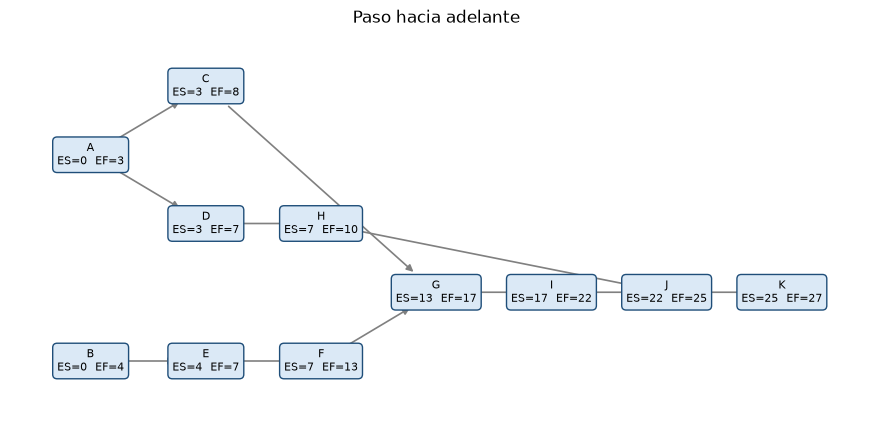

In [18]:
orden = list(act.index)
ES, EF = {}, {}
for a in orden:
    ES[a] = max([EF[p] for p in act.loc[a, "pred"]], default=0)
    EF[a] = ES[a] + act.loc[a, "dur"]
T = max(EF.values())

display(pd.DataFrame({"ES": ES, "EF": EF}))
print("Duración total del proyecto:", T, "días hábiles")

fig, ax = plt.subplots(figsize=(11, 5))
dibujar_red(ax, lambda a: f"{a}\nES={ES[a]}  EF={EF[a]}", titulo="Paso hacia adelante")
plt.show()

## Paso 5: Paso hacia atrás (tiempos tardíos)
Se recorren las actividades de fin a inicio:

LF(a) = min(LS de sus sucesoras), con LF = T si no tiene sucesoras; LS(a) = LF(a) − duración(a)

Primero se obtiene la lista de sucesoras de cada actividad.

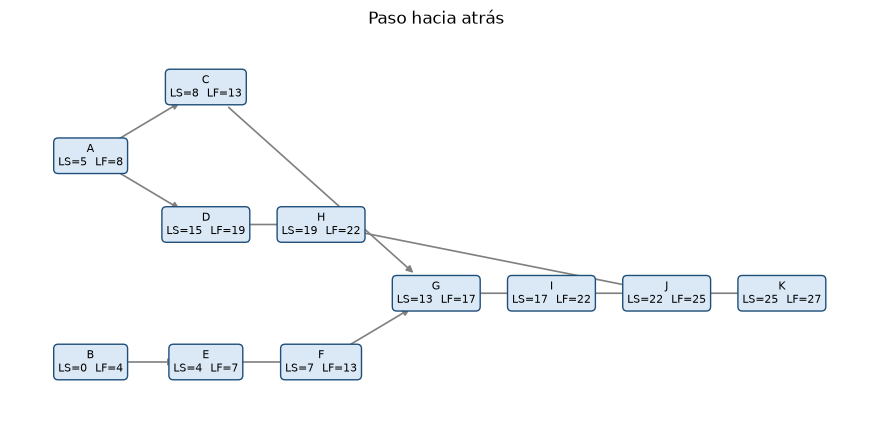

In [19]:
suc = {a: [b for b in orden if a in act.loc[b, "pred"]] for a in orden}
LS, LF = {}, {}
for a in reversed(orden):
    LF[a] = min([LS[s] for s in suc[a]], default=T)
    LS[a] = LF[a] - act.loc[a, "dur"]

fig, ax = plt.subplots(figsize=(11, 5))
dibujar_red(ax, lambda a: f"{a}\nLS={LS[a]}  LF={LF[a]}", titulo="Paso hacia atrás")
plt.show()

## Paso 6: Holguras y ruta crítica
- **Holgura** = LS − ES: días que una actividad puede retrasarse sin afectar la duración total.
- **Actividad crítica**: holgura = 0. Las críticas forman la ruta crítica.

Verificación: la suma de duraciones de la ruta crítica debe ser igual a T.

,dur,ES,EF,LS,LF,holgura,critica
A,3,0,3,5,8,5,False
B,4,0,4,0,4,0,True
C,5,3,8,8,13,5,False
D,4,3,7,15,19,12,False
E,3,4,7,4,7,0,True
F,6,7,13,7,13,0,True
G,4,13,17,13,17,0,True
H,3,7,10,19,22,12,False
I,5,17,22,17,22,0,True
J,3,22,25,22,25,0,True


Ruta crítica: B -> E -> F -> G -> I -> J -> K
Suma de duraciones críticas: 27 | T = 27


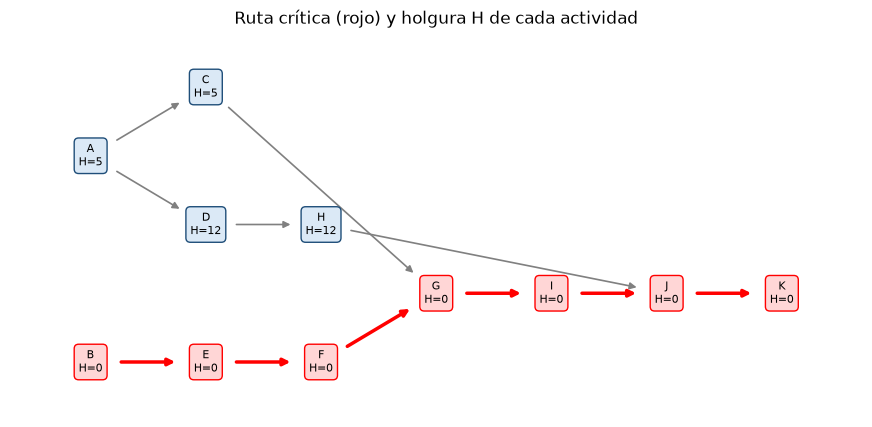

In [20]:
res = pd.DataFrame({"dur": act["dur"], "ES": ES, "EF": EF, "LS": LS, "LF": LF})
res["holgura"] = res["LS"] - res["ES"]
res["critica"] = res["holgura"] == 0
display(res)

criticas = list(res.index[res["critica"]])
print("Ruta crítica:", " -> ".join(criticas))
print("Suma de duraciones críticas:", res.loc[criticas, "dur"].sum(), "| T =", T)

fig, ax = plt.subplots(figsize=(11, 5))
dibujar_red(ax, lambda a: f"{a}\nH={res.loc[a,'holgura']}", criticas,
            "Ruta crítica (rojo) y holgura H de cada actividad")
plt.show()

## Paso 7: Diagrama de Gantt
Cada barra empieza en su inicio temprano (ES). En **rojo** las actividades críticas; en **azul** las no críticas; la zona **gris rayada** es la holgura disponible.

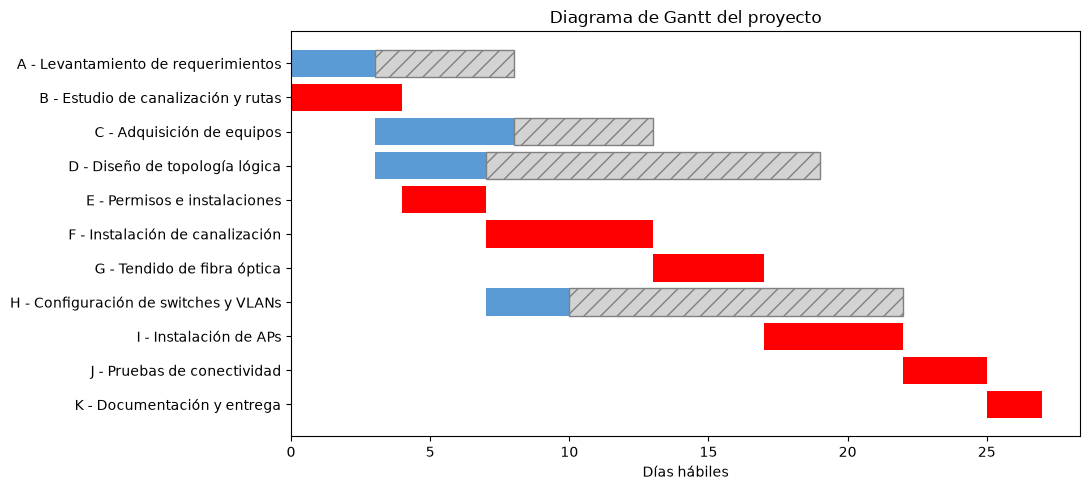

In [21]:
fig, ax = plt.subplots(figsize=(11, 5))
for i, a in enumerate(orden):
    ax.barh(i, res.loc[a, "dur"], left=res.loc[a, "ES"],
            color="red" if a in criticas else "#5b9bd5")
    if res.loc[a, "holgura"] > 0:
        ax.barh(i, res.loc[a, "holgura"], left=res.loc[a, "EF"],
                color="lightgray", hatch="//", edgecolor="gray")
ax.set_yticks(range(len(orden)))
ax.set_yticklabels([f"{a} - {act.loc[a,'nombre']}" for a in orden])
ax.invert_yaxis()
ax.set_xlabel("Días hábiles")
ax.set_title("Diagrama de Gantt del proyecto")
plt.tight_layout()
plt.show()

## Paso 8: Verificación con SciPy
La duración mínima del proyecto también se puede obtener con programación lineal. Variables: el inicio sA, ..., sK de cada actividad y la duración total T.

Minimizar T, sujeto a:
- s_a >= s_p + dur_p para cada predecesora p de a
- T >= s_a + dur_a para toda actividad a
- s_a >= 0

Si `linprog` da el mismo valor que nuestro CPM, el cálculo es correcto.

In [22]:
idx = {a: i for i, a in enumerate(orden)}
n = len(orden)
A_ub, b_ub = [], []

for a in orden:                          # precedencias
    for p in act.loc[a, "pred"]:
        fila = np.zeros(n + 1); fila[idx[p]] = 1; fila[idx[a]] = -1
        A_ub.append(fila); b_ub.append(-act.loc[p, "dur"])
for a in orden:                          # T >= fin de cada actividad
    fila = np.zeros(n + 1); fila[idx[a]] = 1; fila[n] = -1
    A_ub.append(fila); b_ub.append(-act.loc[a, "dur"])

c = np.zeros(n + 1); c[n] = 1            # minimizar T
lp = linprog(c, A_ub=np.array(A_ub), b_ub=b_ub, bounds=(0, None), method="highs")

print("Duración con CPM      :", T)
print("Duración con linprog  :", lp.fun)
print("¿Coinciden?           :", np.isclose(lp.fun, T))

Duración con CPM      : 27
Duración con linprog  : 27.0
¿Coinciden?           : True


---
### 1. Práctica 3
Determinación de la Ruta de Menor Latencia entre el Router Perimetral y el Servidor de Base de Datos mediante el Algoritmo de Dijkstra.

### 2. Descripción y Planteamiento
En el Centro de Datos del **Centro Universitario UAEM Zumpango**, los paquetes de datos deben viajar desde el **Router Perimetral (RP)**, que recibe el tráfico externo, hasta el **Servidor de Base de Datos (SBD)**, donde se almacena la información académica crítica de los estudiantes.

La red está compuesta por **8 nodos** (routers y servidores) interconectados mediante enlaces de fibra óptica. Cada enlace tiene asociado un **peso que representa la latencia en milisegundos (ms)**, la cual depende de factores como la distancia física, la cantidad de saltos intermedios y la carga de procesamiento en cada dispositivo.

El objetivo es determinar la **ruta de menor latencia** entre el nodo origen (RP) y el nodo destino (SBD), garantizando la transmisión más eficiente de los paquetes de datos. Este problema se modela como la búsqueda del **camino más corto en un grafo ponderado**, resolviéndose mediante el **Algoritmo de Dijkstra**.

---

### 3. Definición de Nodos y Enlaces de la Red

La red está conformada por los siguientes **8 nodos**, cada uno con un rol específico dentro de la infraestructura de TI:

| Código | Nodo                    | Función en la Red                          |
|:------:|:------------------------|:-------------------------------------------|
| RP     | Router Perimetral       | Punto de entrada de tráfico externo        |
| FW     | Firewall Principal      | Filtrado y seguridad de red                |
| SW     | Servidor Web            | Alojamiento de portales académicos         |
| SA     | Servidor de Aplicaciones| Ejecución de sistemas institucionales      |
| SBD    | Servidor de Base de Datos| Almacenamiento de datos críticos          |
| SC     | Servidor de Correo      | Gestión de cuentas institucionales         |
| SR     | Servidor de Respaldo    | Copias de seguridad y redundancia          |
| CM     | Centro de Monitoreo     | Supervisión de la infraestructura          |

Las posibles rutas entre nodos y sus respectivas latencias (en milisegundos) se muestran en la siguiente tabla:

| Origen | Destino | Latencia (ms) |
|:------:|:-------:|:-------------:|
| RP     | FW      | 5             |
| RP     | CM      | 15            |
| FW     | SW      | 10            |
| FW     | SA      | 12            |
| SW     | SBD     | 15            |
| SA     | SBD     | 5             |
| SA     | SC      | 10            |
| SC     | SR      | 10            |
| SR     | SBD     | 20            |
| CM     | SA      | 25            |
| CM     | SC      | 30            |

**Nodo origen:** Router Perimetral (RP)  
**Nodo destino:** Servidor de Base de Datos (SBD)

En esta primera etapa se importan las bibliotecas necesarias para desarrollar el algoritmo, manipular los datos y generar las gráficas.

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import dijkstra

Se definen los ocho nodos que conforman la infraestructura de red del Centro Universitario UAEM Zumpango.
Posteriormente, se registran los enlaces entre los dispositivos y sus respectivas latencias en milisegundos.
Para este ejercicio se considera que los enlaces son bidireccionales, es decir, que la comunicación puede realizarse en ambos sentidos con el mismo peso.

In [24]:
nodos = ['RP', 'FW', 'SW', 'SA', 'SBD', 'SC', 'SR', 'CM']

enlaces = [
    ('RP', 'FW', 5),
    ('RP', 'CM', 15),
    ('FW', 'SW', 10),
    ('FW', 'SA', 12),
    ('SW', 'SBD', 15),
    ('SA', 'SBD', 5),
    ('SA', 'SC', 10),
    ('SC', 'SR', 10),
    ('SR', 'SBD', 20),
    ('CM', 'SA', 25),
    ('CM', 'SC', 30)
]

df = pd.DataFrame(enlaces, columns=['Origen', 'Destino', 'Latencia'])

display(df)

,Origen,Destino,Latencia
0,RP,FW,5
1,RP,CM,15
2,FW,SW,10
3,FW,SA,12
4,SW,SBD,15
5,SA,SBD,5
6,SA,SC,10
7,SC,SR,10
8,SR,SBD,20
9,CM,SA,25


El algoritmo de Dijkstra necesita conocer las conexiones existentes entre los nodos y el costo de cada enlace.
Para ello, se construye una matriz de adyacencia de tamaño 8 × 8.
Cada posición representa la latencia entre dos nodos:
Si existe una conexión, se almacena su latencia.
Si no existe conexión, se utiliza infinito (np.inf).
La diagonal principal contiene ceros, porque la distancia de un nodo hacia sí mismo es cero.

In [25]:
n = len(nodos)

matriz = np.full((n, n), np.inf)
np.fill_diagonal(matriz, 0)

for origen, destino, peso in enlaces:
    i = nodos.index(origen)
    j = nodos.index(destino)

    matriz[i, j] = peso
    matriz[j, i] = peso

df_matriz = pd.DataFrame(matriz, index=nodos, columns=nodos)

display(df_matriz)

,RP,FW,SW,SA,SBD,SC,SR,CM
RP,0.0,5.0,inf,inf,inf,inf,inf,15.0
FW,5.0,0.0,10.0,12.0,inf,inf,inf,inf
SW,inf,10.0,0.0,inf,15.0,inf,inf,inf
SA,inf,12.0,inf,0.0,5.0,10.0,inf,25.0
SBD,inf,inf,15.0,5.0,0.0,inf,20.0,inf
SC,inf,inf,inf,10.0,inf,0.0,10.0,30.0
SR,inf,inf,inf,inf,20.0,10.0,0.0,inf
CM,15.0,inf,inf,25.0,inf,30.0,inf,0.0


Antes de ejecutar Dijkstra, se representa gráficamente la infraestructura de red.
Cada círculo representa un dispositivo y cada línea representa un enlace de comunicación. Los números indican la latencia en milisegundos.
Esta gráfica permite identificar visualmente las conexiones disponibles entre los dispositivos.

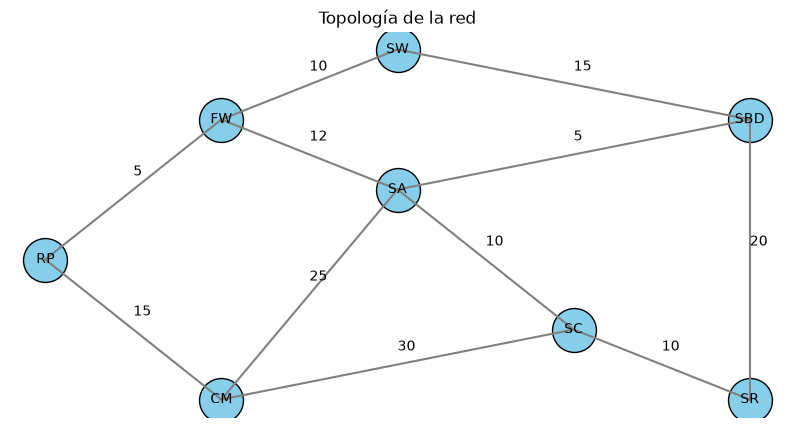

In [26]:
posiciones = {
    'RP': (0, 1),
    'FW': (1, 2),
    'CM': (1, 0),
    'SW': (2, 2.5),
    'SA': (2, 1.5),
    'SC': (3, 0.5),
    'SBD': (4, 2),
    'SR': (4, 0)
}

def graficar_red():
    plt.figure(figsize=(10, 5))

    for o, d, peso in enlaces:
        x = [posiciones[o][0], posiciones[d][0]]
        y = [posiciones[o][1], posiciones[d][1]]

        plt.plot(x, y, color='gray', linewidth=1.5)
        plt.text(
            (x[0] + x[1])/2,
            (y[0] + y[1])/2 + 0.1,
            str(peso),
            fontsize=10
        )

    for nodo, (x, y) in posiciones.items():
        plt.scatter(x, y, s=1000, color='skyblue',
                    edgecolors='black')
        plt.text(x, y, nodo, ha='center',
                 va='center', fontsize=10)

    plt.title('Topología de la red')
    plt.axis('off')
    plt.show()

graficar_red()

En esta etapa se establecen los valores iniciales del algoritmo.
Dijkstra utiliza tres elementos principales:
Distancias: almacenan la menor latencia conocida desde el nodo origen hasta cada nodo.
Visitados: indican qué nodos ya fueron procesados.
Predecesores: almacenan el nodo anterior de cada conexión para reconstruir la ruta final.
Inicialmente, la distancia del nodo RP es cero, mientras que las distancias de los demás nodos son infinitas, porque todavía no se conoce una ruta hacia ellos.

In [27]:
origen = 'RP'
destino = 'SBD'

distancias = np.full(n, np.inf)
visitados = np.zeros(n, dtype=bool)
predecesores = np.full(n, -1, dtype=int)

distancias[nodos.index(origen)] = 0

tabla_inicial = pd.DataFrame({
    'Nodo': nodos,
    'Distancia': distancias,
    'Visitado': visitados
})

display(tabla_inicial)

,Nodo,Distancia,Visitado
0,RP,0.0,False
1,FW,inf,False
2,SW,inf,False
3,SA,inf,False
4,SBD,inf,False
5,SC,inf,False
6,SR,inf,False
7,CM,inf,False


El procedimiento consiste en:
Seleccionar el nodo no visitado que tenga la menor distancia acumulada.
Marcarlo como visitado.
Revisar sus nodos vecinos.
Calcular la nueva distancia acumulada.
Si la nueva distancia es menor que la registrada, actualizarla.
Guardar el predecesor para reconstruir posteriormente la ruta.
Este procedimiento se repite hasta llegar al nodo destino o hasta que no existan más nodos alcanzables.
Se guardará una copia del estado del algoritmo después de cada iteración para poder visualizar su evolución.

In [28]:
historial = []

while True:

    disponibles = np.where(~visitados, distancias, np.inf)

    actual = np.argmin(disponibles)

    if np.isinf(disponibles[actual]):
        break

    visitados[actual] = True

    for vecino in range(n):

        if not visitados[vecino] and matriz[actual, vecino] != np.inf:

            nueva_distancia = (
                distancias[actual] + matriz[actual, vecino]
            )

            if nueva_distancia < distancias[vecino]:

                distancias[vecino] = nueva_distancia
                predecesores[vecino] = actual

    historial.append({
        'actual': actual,
        'distancias': distancias.copy(),
        'visitados': visitados.copy(),
        'predecesores': predecesores.copy()
    })

    if actual == nodos.index(destino):
        break

En este apartado se representa gráficamente el comportamiento del algoritmo durante cada iteración.
En las gráficas se identifican:
Los nodos visitados.
El nodo que se está procesando.
Las distancias acumuladas desde RP.
Las conexiones que forman el árbol de predecesores.
De esta manera, se observa cómo Dijkstra va encontrando rutas más eficientes hasta alcanzar el servidor de base de datos.

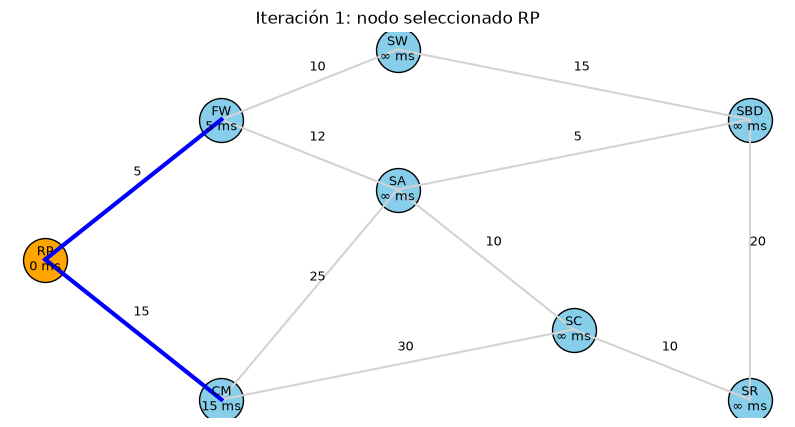

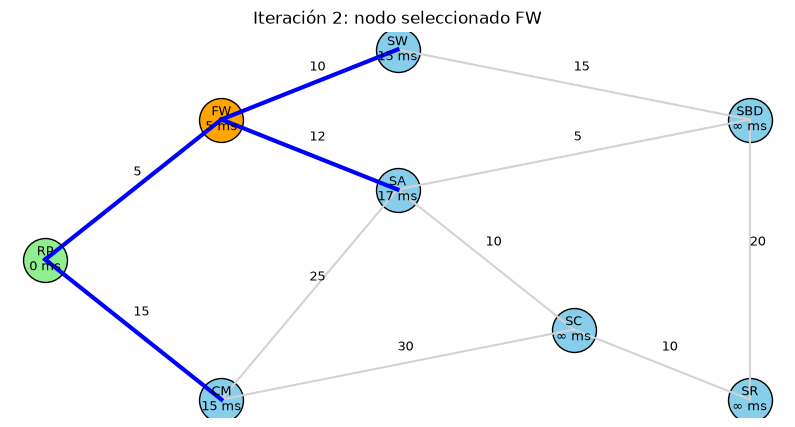

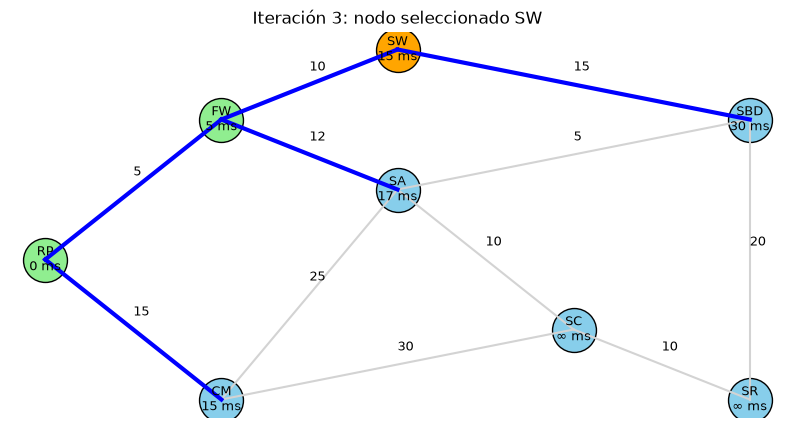

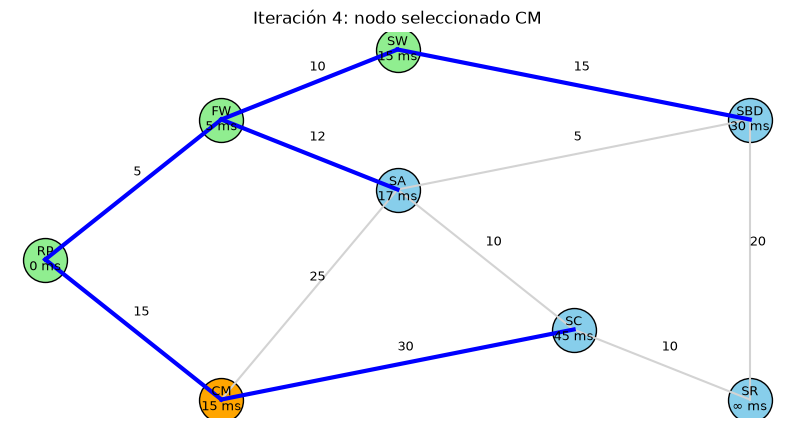

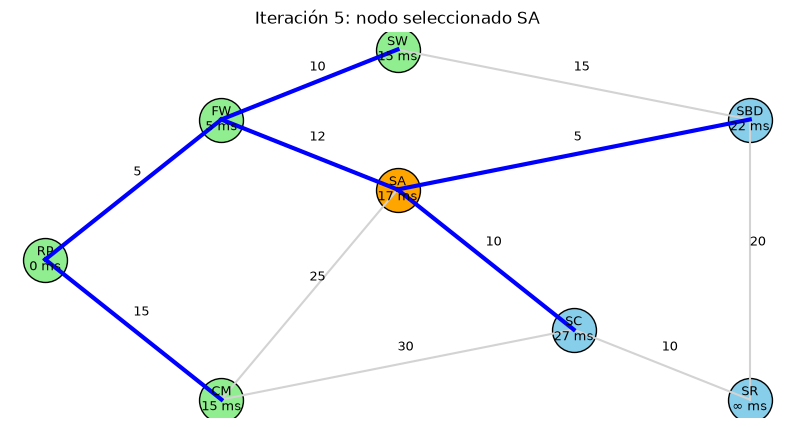

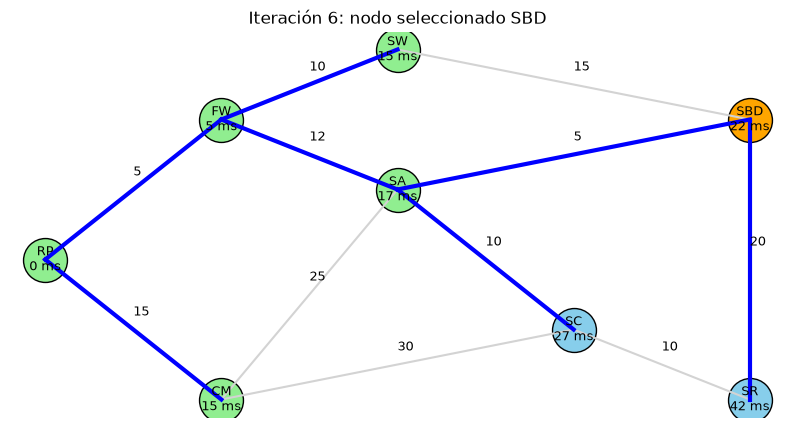

In [29]:
def graficar_iteracion(paso, numero):

    actual = paso['actual']
    dist = paso['distancias']
    visit = paso['visitados']
    pred = paso['predecesores']

    plt.figure(figsize=(10, 5))

    # Dibujar enlaces
    for o, d, peso in enlaces:
        x = [posiciones[o][0], posiciones[d][0]]
        y = [posiciones[o][1], posiciones[d][1]]
        plt.plot(x, y, color='lightgray', linewidth=1.5)

        plt.text((x[0]+x[1])/2, (y[0]+y[1])/2+0.1,
                 str(peso), fontsize=9)

    # Dibujar árbol de predecesores
    for i, p in enumerate(pred):
        if p != -1:
            x = [posiciones[nodos[p]][0], posiciones[nodos[i]][0]]
            y = [posiciones[nodos[p]][1], posiciones[nodos[i]][1]]
            plt.plot(x, y, color='blue', linewidth=3)

    # Dibujar nodos
    for i, nodo in enumerate(nodos):

        x, y = posiciones[nodo]

        if i == actual:
            color = 'orange'
        elif visit[i]:
            color = 'lightgreen'
        else:
            color = 'skyblue'

        plt.scatter(x, y, s=1000, color=color,
                    edgecolors='black')

        valor = '∞' if np.isinf(dist[i]) else f'{dist[i]:.0f}'

        plt.text(x, y, f'{nodo}\n{valor} ms',
                 ha='center', va='center', fontsize=9)

    plt.title(f'Iteración {numero}: nodo seleccionado {nodos[actual]}')
    plt.axis('off')
    plt.show()


for i, paso in enumerate(historial, start=1):
    graficar_iteracion(paso, i)

Además de las gráficas, se presenta una tabla con las distancias acumuladas en cada iteración.
Esto permite analizar numéricamente cómo se actualizan los valores y qué nodos ya fueron visitados.
El símbolo infinito indica que todavía no se ha encontrado una ruta desde el origen hacia ese nodo.

In [30]:
for i, paso in enumerate(historial, start=1):

    tabla = pd.DataFrame({
        'Nodo': nodos,
        'Distancia (ms)': paso['distancias'],
        'Visitado': paso['visitados']
    })

    print(f'Iteración {i}: {nodos[paso["actual"]]}')
    display(tabla)

Iteración 1: RP


,Nodo,Distancia (ms),Visitado
0,RP,0.0,True
1,FW,5.0,False
2,SW,inf,False
3,SA,inf,False
4,SBD,inf,False
5,SC,inf,False
6,SR,inf,False
7,CM,15.0,False


Iteración 2: FW


,Nodo,Distancia (ms),Visitado
0,RP,0.0,True
1,FW,5.0,True
2,SW,15.0,False
3,SA,17.0,False
4,SBD,inf,False
5,SC,inf,False
6,SR,inf,False
7,CM,15.0,False


Iteración 3: SW


,Nodo,Distancia (ms),Visitado
0,RP,0.0,True
1,FW,5.0,True
2,SW,15.0,True
3,SA,17.0,False
4,SBD,30.0,False
5,SC,inf,False
6,SR,inf,False
7,CM,15.0,False


... (2 outputs left out)

Iteración 5: SA


,Nodo,Distancia (ms),Visitado
0,RP,0.0,True
1,FW,5.0,True
2,SW,15.0,True
3,SA,17.0,True
4,SBD,22.0,False
5,SC,27.0,False
6,SR,inf,False
7,CM,15.0,True


Iteración 6: SBD


,Nodo,Distancia (ms),Visitado
0,RP,0.0,True
1,FW,5.0,True
2,SW,15.0,True
3,SA,17.0,True
4,SBD,22.0,True
5,SC,27.0,False
6,SR,42.0,False
7,CM,15.0,True


Una vez alcanzado el nodo destino, se utilizan los predecesores almacenados para reconstruir el camino.
El procedimiento comienza en SBD y retrocede hasta llegar a RP.
Posteriormente, se invierte el orden para obtener la ruta desde el origen hasta el destino.

In [31]:
ruta = []

actual = nodos.index(destino)

while actual != -1:
    ruta.append(nodos[actual])
    actual = predecesores[actual]

ruta.reverse()

latencia_total = distancias[nodos.index(destino)]

print('Ruta de menor latencia:')
print(' -> '.join(ruta))

print(f'Latencia total: {latencia_total} ms')

Ruta de menor latencia:
RP -> FW -> SA -> SBD
Latencia total: 22.0 ms


Se realiza una última representación gráfica para destacar exclusivamente la ruta encontrada por el algoritmo.
Las conexiones que forman el camino óptimo se muestran en color rojo, mientras que las demás conexiones permanecen en gris.
Esto permite identificar visualmente el recorrido que deben seguir los paquetes de datos para alcanzar el servidor de base de datos con la menor latencia.

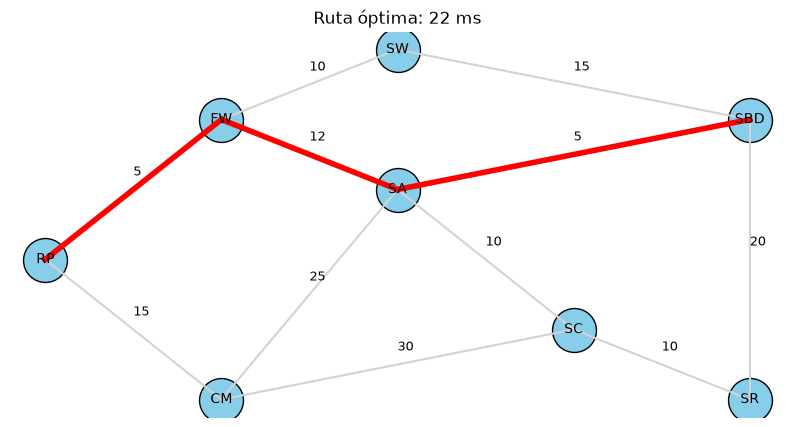

In [32]:
plt.figure(figsize=(10, 5))

# Todos los enlaces
for o, d, peso in enlaces:
    x = [posiciones[o][0], posiciones[d][0]]
    y = [posiciones[o][1], posiciones[d][1]]

    plt.plot(x, y, color='lightgray', linewidth=1.5)
    plt.text((x[0]+x[1])/2, (y[0]+y[1])/2+0.1,
             str(peso), fontsize=9)

# Ruta óptima
for i in range(len(ruta)-1):
    o, d = ruta[i], ruta[i+1]

    x = [posiciones[o][0], posiciones[d][0]]
    y = [posiciones[o][1], posiciones[d][1]]

    plt.plot(x, y, color='red', linewidth=4)

# Nodos
for nodo, (x, y) in posiciones.items():
    plt.scatter(x, y, s=1000, color='skyblue',
                edgecolors='black')
    plt.text(x, y, nodo, ha='center',
             va='center', fontsize=10)

plt.title(f'Ruta óptima: {latencia_total:.0f} ms')
plt.axis('off')
plt.show()

Finalmente, se utiliza la función dijkstra() de SciPy para comprobar que el resultado obtenido mediante nuestra implementación coincide con el resultado de la biblioteca.
Para ello, se transforma la matriz de adyacencia en una matriz dispersa, donde los ceros representan la ausencia de conexión.

In [33]:
matriz_scipy = np.where(np.isfinite(matriz), matriz, 0)

grafo = csr_matrix(matriz_scipy)

resultado = dijkstra(
    grafo,
    directed=False,
    indices=nodos.index(origen)
)

print('Comprobación con SciPy')
print(f'Latencia desde RP hasta SBD: '
      f'{resultado[nodos.index(destino)]} ms')

Comprobación con SciPy
Latencia desde RP hasta SBD: 22.0 ms


---
### 1. Práctica 4
Optimización del Dimensionamiento de Servidores Virtuales en el Centro de Datos mediante Programación Lineal.

### 2. Descripción y Planteamiento
Tras haber desplegado la red WiFi del campus (Prácticas 1 y 2) y configurado el enrutamiento óptimo (Práctica 3), el **Centro de Datos del Centro Universitario UAEM Zumpango** debe dimensionar la capacidad de cómputo para atender la demanda de los servicios académicos institucionales: portales web, sistemas de gestión escolar, bases de datos y servicios de correo.

El departamento de TI cuenta con un **presupuesto limitado**, una **capacidad máxima de consumo eléctrico** y un **espacio físico restringido** en los racks. Se deben adquirir dos tipos de servidores virtuales (VMs):

- **Tipo A (Alto Rendimiento):** destinadas a bases de datos y sistemas críticos.
- **Tipo B (Estándar):** destinadas a servicios web, correo y aplicaciones generales.

Cada tipo de servidor aporta diferente capacidad de procesamiento (medida en **UPH: Unidades de Procesamiento por Hora**) y tiene distintos costos, consumos y requerimientos de espacio. El objetivo es **maximizar la capacidad total de procesamiento** del Centro de Datos respetando las restricciones presupuestales, eléctricas y físicas.

Este problema se modela como un **Problema de Programación Lineal (PL)**.

---

### 3. Definición de Parámetros del Problema

A continuación se presentan las características de cada tipo de servidor y los recursos disponibles:

#### Características de los Servidores Virtuales

| Parámetro                  | Servidor Tipo A | Servidor Tipo B |
|:---------------------------|:---------------:|:---------------:|
| Capacidad de procesamiento | 120 UPH         | 80 UPH          |
| Costo de adquisición       | $15,000 MXN     | $9,000 MXN      |
| Consumo eléctrico          | 450 W           | 280 W           |
| Espacio en rack            | 3 U             | 2 U             |

#### Recursos Disponibles (Restricciones)

| Recurso                | Disponibilidad Máxima      |
|:-----------------------|:--------------------------:|
| Presupuesto total      | $180,000 MXN               |
| Capacidad eléctrica    | 3,200 W                    |
| Espacio en rack        | 50 U (unidades de rack)    |

**Nota:** 
- **UPH** = Unidades de Procesamiento por Hora (métrica interna de capacidad de cómputo).
- **U** = Unidad de rack (1U = 4.445 cm de altura estándar).
- Se asume que las variables son **enteras no negativas** (no se pueden adquirir fracciones de servidores).

Se importan las bibliotecas necesarias para desarrollar el modelo matemático, organizar los datos, resolver el problema y visualizar los resultados.

In [34]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.optimize import milp, LinearConstraint, Bounds

Se establecen las características de los dos tipos de servidores que se pueden adquirir.
Cada servidor proporciona una capacidad de procesamiento diferente y consume determinados recursos económicos, eléctricos y físicos.
Los datos se almacenan en arreglos de NumPy para facilitar su utilización en el modelo matemático.

In [35]:
servidores = ['Tipo A', 'Tipo B']

capacidad = np.array([120, 80])

costo = np.array([15000, 9000])

energia = np.array([450, 280])

espacio = np.array([3, 2])

recursos = np.array([180000, 3200, 50])

Se construye una tabla para visualizar las características de cada servidor y otra para representar los recursos disponibles.
Esto permite comprobar los parámetros antes de construir el modelo de optimización.

In [36]:
df_servidores = pd.DataFrame({
    'Servidor': servidores,
    'Procesamiento (UPH)': capacidad,
    'Costo (MXN)': costo,
    'Consumo (W)': energia,
    'Espacio (U)': espacio
})

df_recursos = pd.DataFrame({
    'Recurso': ['Presupuesto', 'Electricidad', 'Espacio'],
    'Disponibilidad': recursos,
    'Unidad': ['MXN', 'W', 'U']
})

display(df_servidores)
display(df_recursos)

,Servidor,Procesamiento (UPH),Costo (MXN),Consumo (W),Espacio (U)
0,Tipo A,120,15000,450,3
1,Tipo B,80,9000,280,2


,Recurso,Disponibilidad,Unidad
0,Presupuesto,180000,MXN
1,Electricidad,3200,W
2,Espacio,50,U


Las variables de decisión representan la cantidad de servidores que se adquirirán de cada tipo.
: cantidad de servidores Tipo A.
: cantidad de servidores Tipo B.
Ambas variables deben ser enteras y no negativas.
El algoritmo determinará los valores de  y  que proporcionen la mayor capacidad de procesamiento posible.

In [37]:
variables = ['x (Tipo A)', 'y (Tipo B)']

print('Variables de decisión:')
print('x = Cantidad de servidores Tipo A')
print('y = Cantidad de servidores Tipo B')

Variables de decisión:
x = Cantidad de servidores Tipo A
y = Cantidad de servidores Tipo B


La función objetivo representa el procesamiento total que se desea maximizar.
Cada servidor Tipo A aporta 120 UPH y cada servidor Tipo B aporta 80 UPH.
Por lo tanto, la función objetivo es:
Donde  representa la capacidad total de procesamiento del Centro de Datos.
Como SciPy resuelve problemas de minimización, se multiplican los coeficientes de la función objetivo por - 1

In [38]:
funcion_objetivo = np.array([120, 80])

# SciPy minimiza, por eso se utilizan valores negativos
objetivo = -funcion_objetivo

print('Función objetivo:')
print('Maximizar Z = 120x + 80y')

Función objetivo:
Maximizar Z = 120x + 80y


El costo de los servidores no debe superar los $180,000 MXN.
Restricción 2. Consumo eléctrico
El consumo total no debe superar los 3,200 W.
Restricción 3. Espacio en rack
El espacio ocupado no debe superar las 50 unidades de rack.
Restricción 4. No negatividad e integralidad

In [39]:
# Matriz de restricciones
A = np.array([
    [15000, 9000],
    [450, 280],
    [3, 2]
])

# Límites máximos
b = np.array([180000, 3200, 50])

df_restricciones = pd.DataFrame(
    A,
    columns=['Tipo A', 'Tipo B'],
    index=['Presupuesto', 'Electricidad', 'Espacio']
)

df_restricciones['Límite'] = b

display(df_restricciones)

,Tipo A,Tipo B,Límite
Presupuesto,15000,9000,180000
Electricidad,450,280,3200
Espacio,3,2,50


En esta etapa se representan gráficamente las tres restricciones del problema.
El eje X representa la cantidad de servidores Tipo A y el eje Y representa la cantidad de servidores Tipo B.
Cada línea representa el límite máximo permitido para un recurso:
Presupuesto.
Consumo eléctrico.
Espacio en rack.
La región que se encuentra por debajo de todas las restricciones representa las combinaciones que cumplen simultáneamente con los recursos disponibles.

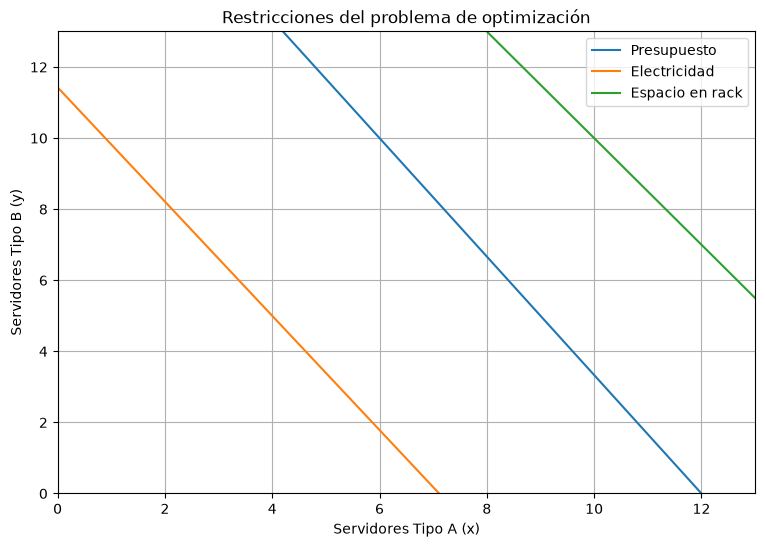

In [40]:
x = np.linspace(0, 13, 300)

plt.figure(figsize=(9, 6))

plt.plot(x, (180000 - 15000*x)/9000,
         label='Presupuesto')

plt.plot(x, (3200 - 450*x)/280,
         label='Electricidad')

plt.plot(x, (50 - 3*x)/2,
         label='Espacio en rack')

plt.xlim(0, 13)
plt.ylim(0, 13)

plt.xlabel('Servidores Tipo A (x)')
plt.ylabel('Servidores Tipo B (y)')
plt.title('Restricciones del problema de optimización')

plt.grid(True)
plt.legend()
plt.show()

Una combinación es factible cuando cumple simultáneamente todas las restricciones del problema.
Debido a que no se pueden adquirir fracciones de servidores, únicamente se consideran valores enteros para  y .
En esta etapa se generan las posibles combinaciones de servidores y se comprueba cuáles cumplen las restricciones establecidas.
Las combinaciones factibles se representarán mediante puntos en una gráfica.

In [41]:
combinaciones = []

for x in range(14):
    for y in range(14):

        consumo = A @ np.array([x, y])

        if np.all(consumo <= b):
            combinaciones.append([x, y])

df_factibles = pd.DataFrame(
    combinaciones,
    columns=['Tipo A', 'Tipo B']
)

display(df_factibles)

,Tipo A,Tipo B
0,0,0
1,0,1
2,0,2
3,0,3
4,0,4
5,0,5
6,0,6
7,0,7
8,0,8
9,0,9


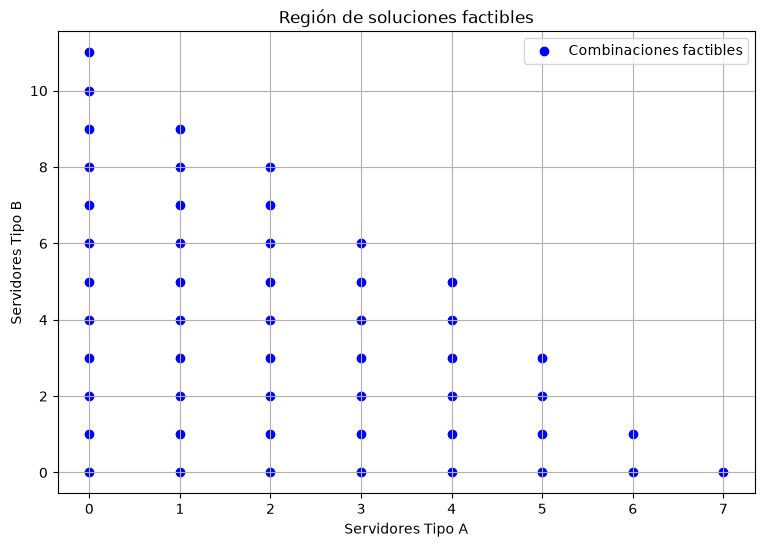

In [42]:
plt.figure(figsize=(9, 6))

plt.scatter(
    df_factibles['Tipo A'],
    df_factibles['Tipo B'],
    color='blue',
    label='Combinaciones factibles'
)

plt.xlabel('Servidores Tipo A')
plt.ylabel('Servidores Tipo B')

plt.title('Región de soluciones factibles')
plt.grid(True)
plt.legend()
plt.show()

Una vez definidas las variables, la función objetivo y las restricciones, se procede a resolver el problema utilizando la función milp() de SciPy.
Esta función permite resolver problemas de optimización lineal con variables enteras.
Se establecen los siguientes parámetros:
Función objetivo: maximizar la capacidad de procesamiento.
Restricciones: presupuesto, electricidad y espacio.
Límites inferiores: cero servidores.
Variables enteras: no se permiten fracciones de servidores.
La función devuelve los valores óptimos de las variables de decisión.

In [43]:
resultado = milp(
    c=objetivo,
    integrality=np.ones(2),
    bounds=Bounds([0, 0], [np.inf, np.inf]),
    constraints=LinearConstraint(
        A,
        [-np.inf, -np.inf, -np.inf],
        b
    )
)

if resultado.success:
    solucion = np.rint(resultado.x).astype(int)

    print('Optimización realizada correctamente')
    print(f'Servidores Tipo A: {solucion[0]}')
    print(f'Servidores Tipo B: {solucion[1]}')
    print(f'Capacidad máxima: {-resultado.fun:.0f} UPH')
else:
    print('No se encontró una solución óptima')
    print(resultado.message)

Optimización realizada correctamente
Servidores Tipo A: 0
Servidores Tipo B: 11
Capacidad máxima: 880 UPH


En esta etapa se muestra gráficamente la solución obtenida mediante SciPy.
Se representan las combinaciones factibles y se destaca el punto que corresponde a la solución óptima encontrada por el algoritmo.
Este punto representa la cantidad de servidores que proporciona la mayor capacidad de procesamiento sin incumplir las restricciones.

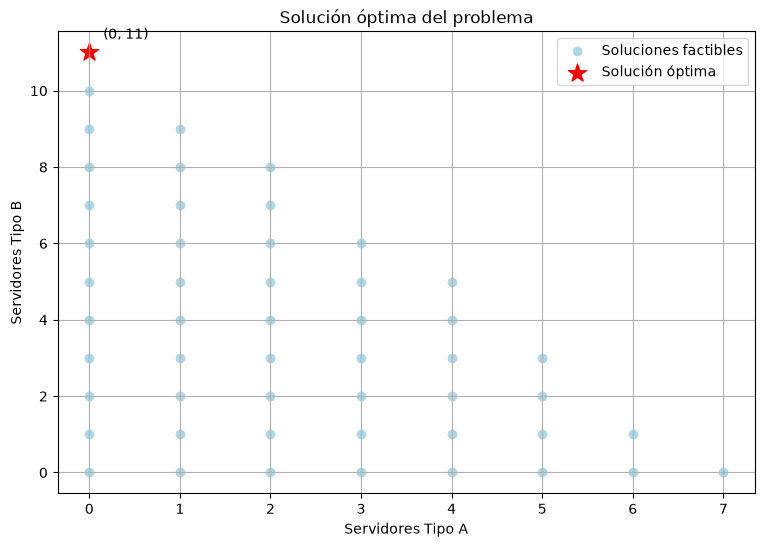

In [44]:
plt.figure(figsize=(9, 6))

plt.scatter(
    df_factibles['Tipo A'],
    df_factibles['Tipo B'],
    color='lightblue',
    label='Soluciones factibles'
)

plt.scatter(
    solucion[0],
    solucion[1],
    color='red',
    s=180,
    marker='*',
    label='Solución óptima'
)

plt.annotate(
    f'({solucion[0]}, {solucion[1]})',
    (solucion[0], solucion[1]),
    xytext=(10, 10),
    textcoords='offset points'
)

plt.xlabel('Servidores Tipo A')
plt.ylabel('Servidores Tipo B')

plt.title('Solución óptima del problema')
plt.grid(True)
plt.legend()
plt.show()

Después de obtener la solución óptima, se calcula cuánto presupuesto, electricidad y espacio en rack se utilizarán.
También se determina cuánto recurso queda disponible después de adquirir los servidores.
Esto permite comprobar que la solución respeta las restricciones del problema.

In [45]:
x_opt, y_opt = solucion

utilizados = A @ solucion
disponibles = b - utilizados

df_resultados = pd.DataFrame({
    'Recurso': ['Presupuesto', 'Electricidad', 'Espacio'],
    'Máximo permitido': b,
    'Utilizado': utilizados,
    'Disponible': disponibles
})

display(df_resultados)

,Recurso,Máximo permitido,Utilizado,Disponible
0,Presupuesto,180000,99000,81000
1,Electricidad,3200,3080,120
2,Espacio,50,22,28


Es importante considerar que un problema de optimización puede tener más de una combinación que alcance el mismo valor máximo de la función objetivo.
Por esta razón, se calcula la capacidad de procesamiento de todas las combinaciones factibles y se identifican aquellas que proporcionan el máximo resultado.
Esto permite conocer si existe una única solución óptima o varias soluciones equivalentes.

In [46]:
df_factibles['Procesamiento (UPH)'] = (
    120 * df_factibles['Tipo A'] +
    80 * df_factibles['Tipo B']
)

maximo = df_factibles['Procesamiento (UPH)'].max()

soluciones_optimas = df_factibles[
    df_factibles['Procesamiento (UPH)'] == maximo
]

print(f'Capacidad máxima: {maximo} UPH')

display(soluciones_optimas)

Capacidad máxima: 880 UPH


,Tipo A,Tipo B,Procesamiento (UPH)
11,0,11,880
30,2,8,880
43,4,5,880


Se representan las diferentes combinaciones que alcanzan la capacidad máxima de procesamiento.
Si existen varias soluciones óptimas, todas aparecerán destacadas en la gráfica.
Esto permite observar que no necesariamente existe una única combinación de servidores que maximice el procesamiento.

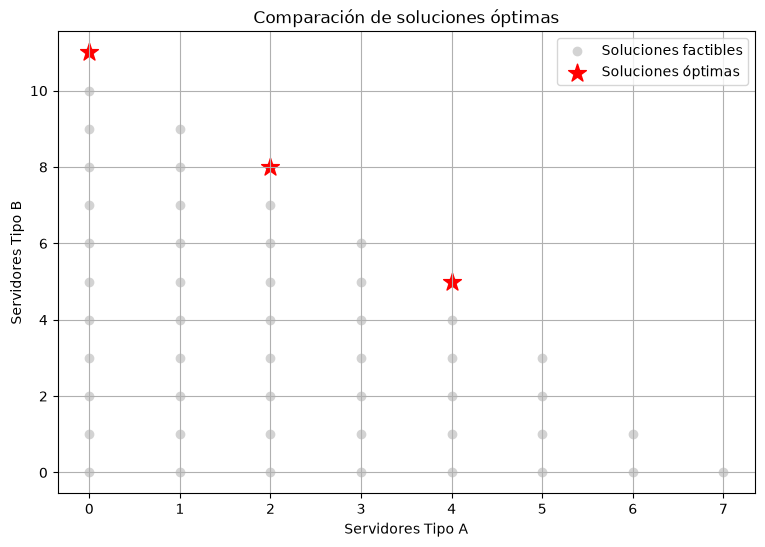

In [47]:
plt.figure(figsize=(9, 6))

plt.scatter(
    df_factibles['Tipo A'],
    df_factibles['Tipo B'],
    color='lightgray',
    label='Soluciones factibles'
)

plt.scatter(
    soluciones_optimas['Tipo A'],
    soluciones_optimas['Tipo B'],
    color='red',
    s=180,
    marker='*',
    label='Soluciones óptimas'
)

plt.xlabel('Servidores Tipo A')
plt.ylabel('Servidores Tipo B')

plt.title('Comparación de soluciones óptimas')
plt.grid(True)
plt.legend()
plt.show()

---
### Conclusiones

---

Zúñiga Melecio Víctor Arturo: Este proyecto me ayudó a ver que la Investigación de Operaciones sí sirve en la vida real. Antes pensaba que era solo teoría, pero al aplicarla a problemas de redes y servidores, entendí que nos va a servir mucho en nuestro trabajo como ingenieros.

Tercero Castro Dante: Lo que más me gustó fue aprender a documentar bien cada paso. Me di cuenta de que no basta con que el código funcione, también hay que saber explicar cómo llegamos al resultado. Además, trabajar en equipo nos obligó a organizarnos mejor.

Medina López Angel Antonio: Me llevé la idea de que los problemas de TI no se resuelven solo programando, también hay que pensarlos bien antes. Ver cómo las cuatro prácticas estaban conectadas me hizo entender que un proyecto real es como un rompecabezas donde todo se relaciona.